In [1]:
# First, we import our libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
 accuracy_score,
 classification_report,
 confusion_matrix
)

In [2]:
#import file
titanic_data = pd.read_csv('data/titanic.csv')

titanic_data.head()

,Survived,Pclass,Name,Sex,Age,SibSp,PaCh,Fare
0,0,3,Mr. Owen Harris Braund,male,22.0,1,0,7.2500
1,1,1,Mrs. John Bradley (Florence Briggs Thayer) Cum...,female,38.0,1,0,71.2833
2,1,3,Miss. Laina Heikkinen,female,26.0,0,0,7.9250
3,1,1,Mrs. Jacques Heath (Lily May Peel) Futrelle,female,35.0,1,0,53.1000
4,0,3,Mr. William Henry Allen,male,35.0,0,0,8.0500


In [3]:
# You can also get this data from seaborn
import seaborn as sns
df = sns.load_dataset("titanic")

In [4]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [5]:
titanic_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 887 entries, 0 to 886
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  887 non-null    int64  
 1   Pclass    887 non-null    int64  
 2   Name      887 non-null    str    
 3   Sex       887 non-null    str    
 4   Age       887 non-null    float64
 5   SibSp     887 non-null    int64  
 6   PaCh      887 non-null    int64  
 7   Fare      887 non-null    float64
dtypes: float64(2), int64(4), str(2)
memory usage: 81.6 KB


In [6]:
titanic_data.describe()

,Survived,Pclass,Age,SibSp,PaCh,Fare
count,887.000000,887.000000,887.000000,887.000000,887.000000,887.00000
mean,0.385569,2.305524,29.471443,0.525366,0.383315,32.30542
std,0.487004,0.836662,14.121908,1.104669,0.807466,49.78204
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.00000
25%,0.000000,2.000000,20.250000,0.000000,0.000000,7.92500
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.45420
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.13750
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.32920


In [7]:
titanic_data["Survived"].value_counts()

Survived
0    545
1    342
Name: count, dtype: int64

In [8]:
titanic_data.isnull().sum()

Survived    0
Pclass      0
Name        0
Sex         0
Age         0
SibSp       0
PaCh        0
Fare        0
dtype: int64

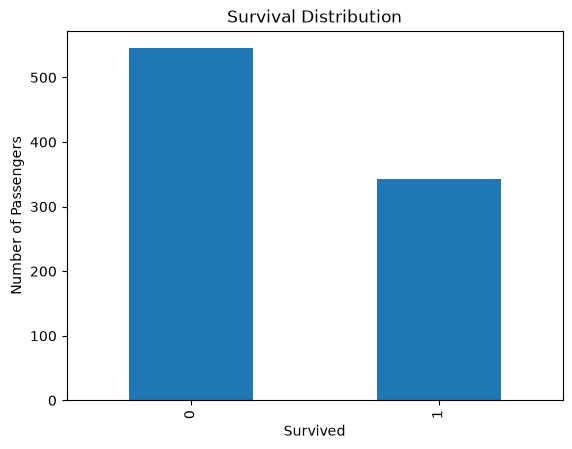

In [9]:
titanic_data["Survived"].value_counts().plot(kind="bar")
plt.title("Survival Distribution")
plt.xlabel("Survived")
plt.ylabel("Number of Passengers")
plt.show()

## What are we looking for?
Before training a model, we should understand our data. We can ask questions such as:

How many passengers survived?

How many passengers did not survive?

Which columns contain missing values?

Which columns are numerical?

Which columns are categorical?

## let's select the important features
### We'll use:

pclass

sex

age

sibsp

parch

fare

In [23]:
features = ['Pclass', 'Sex', 'Age', 'SibSp', 'PaCh', 'Fare']

target = 'Survived'

X = titanic_data[features].copy()
y = titanic_data[target].copy()

In [24]:
titanic_data.columns

Index(['Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'PaCh', 'Fare'], dtype='str')

In [25]:
X.head()

,Pclass,Sex,Age,SibSp,PaCh,Fare
0,3,NaN,22.0,1,0,7.2500
1,1,NaN,38.0,1,0,71.2833
2,3,NaN,26.0,0,0,7.9250
3,1,NaN,35.0,1,0,53.1000
4,3,NaN,35.0,0,0,8.0500


In [26]:
y.head()

0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64

### Clean the Data

Handle Missing Values

Wrong formats

.

.

etc

## Convert Categorical Data

Our machine learning models cannot directly work with text such as: Male and Female. So, we need to convert them into numbers.

In [27]:
X['Sex'] = X['Sex'].apply(lambda x: 1 if x == 'female' else 0)

In [28]:
X.head()

,Pclass,Sex,Age,SibSp,PaCh,Fare
0,3,0,22.0,1,0,7.2500
1,1,0,38.0,1,0,71.2833
2,3,0,26.0,0,0,7.9250
3,1,0,35.0,1,0,53.1000
4,3,0,35.0,0,0,8.0500


### There are other way to do this: using one-hot encoding, map etc

In [21]:
titanic_data['Sex'] = titanic_data['Sex'].map({"female": 1, "male": 0})

In [17]:
X = pd.get_dummies(
 X,
 columns=["Sex"],
 drop_first=True
)

In [18]:
X.head()

,Pclass,Age,SibSp,PaCh,Fare,Sex_1
0,3,22.0,1,0,7.2500,False
1,1,38.0,1,0,71.2833,True
2,3,26.0,0,0,7.9250,True
3,1,35.0,1,0,53.1000,True
4,3,35.0,0,0,8.0500,False


### Split the Dataset
## Train/Test Split

We should not train and test our model using exactly the same data. Instead, we divide the dataset into:

Training data: used to teach the model

Testing data: used to evaluate the model on unseen data

We will use:

80% for training

20% for testing

In [29]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [30]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (709, 6)
Testing data: (178, 6)


### Feature Scaling

Some models aren't affected, but for Logistic Regression, scaling the numerical features is useful.

In [31]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Important
## We use:

fit_transform() on the training data.


But only:


transform() on the testing data.


Why?

The scaler should learn the scaling information from the training data only.

The test data should remain unseen until evaluation.

### 3. Choosing Our Models (Model Selection)

## We will compare three classification algorithms:

1. Logistic Regression

A simple and popular classification algorithm.

2. Decision Tree

Makes decisions by asking a series of questions about the data.

3. Random Forest

Combines multiple decision trees to make predictions.

We will train all three models and compare their performance.



In [32]:
# Train Logistic Regression

logistic_model = LogisticRegression(max_iter=1000)

logistic_model.fit(X_train_scaled, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [33]:
logistic_predictions = logistic_model.predict(X_test_scaled)

logistic_accuracy = accuracy_score(
    y_test,
    logistic_predictions
)

print("Logistic Regression Accuracy:", logistic_accuracy)

Logistic Regression Accuracy: 0.6573033707865169


In [38]:
logistic_predictions[:0]

array([], dtype=int64)

In [39]:
y_test[:10]

433    0
399    0
244    0
492    0
607    0
88     0
411    0
302    0
824    1
164    1
Name: Survived, dtype: int64

In [40]:
print(classification_report(y_test, logistic_predictions))

              precision    recall  f1-score   support

           0       0.68      0.82      0.74       109
           1       0.58      0.41      0.48        69

    accuracy                           0.66       178
   macro avg       0.63      0.61      0.61       178
weighted avg       0.65      0.66      0.64       178



In [41]:
# Train Decision Tree

tree_model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

tree_model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at 

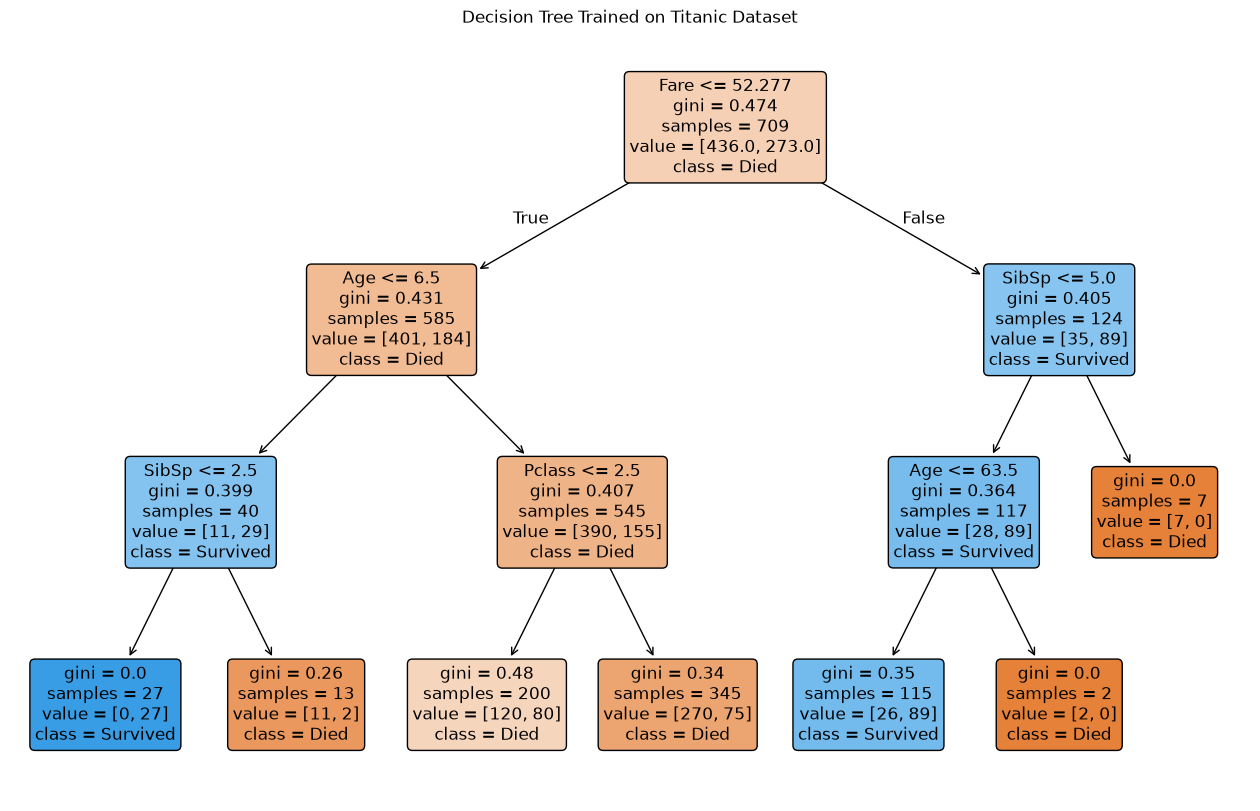

In [42]:
plt.figure(figsize=(16, 10))

plot_tree(
    tree_model, 
    feature_names=features,
    class_names=["Died", "Survived"],
    filled=True, 
    rounded=True,
    fontsize=12,
)

plt.title("Decision Tree Trained on Titanic Dataset")
plt.show()

In [43]:
tree_predictions = tree_model.predict(X_test)

tree_accuracy = accuracy_score(
    y_test,
    tree_predictions
)

print("Decision Tree Accuracy:", tree_accuracy)

Decision Tree Accuracy: 0.6629213483146067


In [44]:
print(classification_report(y_test, tree_predictions))

              precision    recall  f1-score   support

           0       0.66      0.91      0.77       109
           1       0.66      0.28      0.39        69

    accuracy                           0.66       178
   macro avg       0.66      0.59      0.58       178
weighted avg       0.66      0.66      0.62       178



In [45]:
# Train Random Forest

forest_model = RandomForestClassifier(
    random_state=42,
    n_estimators=100,
    max_depth=3
)

forest_model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap:

In [46]:
forest_predictions = forest_model.predict(X_test)

forest_accuracy = accuracy_score(
    y_test,
    forest_predictions
)

print("Random Forest Accuracy:", forest_accuracy)

Random Forest Accuracy: 0.6797752808988764


In [47]:
print(classification_report(y_test, forest_predictions))

              precision    recall  f1-score   support

           0       0.68      0.90      0.77       109
           1       0.68      0.33      0.45        69

    accuracy                           0.68       178
   macro avg       0.68      0.62      0.61       178
weighted avg       0.68      0.68      0.65       178



In [48]:
# Let's compare out Models
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        logistic_accuracy * 100,
        tree_accuracy * 100,
        forest_accuracy * 100
    ]
})
results.round(2)

,Model,Accuracy
0,Logistic Regression,65.73
1,Decision Tree,66.29
2,Random Forest,67.98


In [49]:
results.sort_values(
    by="Accuracy",
    ascending=False
)

,Model,Accuracy
2,Random Forest,67.977528
1,Decision Tree,66.292135
0,Logistic Regression,65.730337


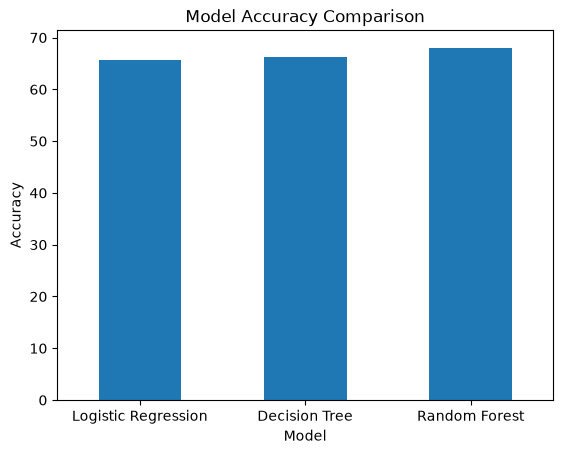

In [50]:
results.plot(
    x="Model",
    y="Accuracy",
    kind="bar",
    legend=False
)

plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.xlabel("Model")

plt.xticks(rotation=0)

plt.show()

### What did we learn?

We trained three different models on the same problem.

The models may produce different results because they learn patterns from the data differently.

At this stage, we have a baseline performance for each model.

Next, we will try to improve the models using hyperparameter tuning.

Remember this? Room for improvement

# Tuning & Optimization (hyperparameters)


In [51]:
# Tune the Decision Tree

tree_params = {
    "max_depth": [2, 3, 4, 5, 6, 8, 10],
}

tree_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    tree_params,
    cv=5,
    scoring="accuracy"
)

tree_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [2, 3, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, wi

In [52]:
print("Best Parameters:")
print(tree_grid.best_params_)

print("Best Cross-Validation Accuracy:")
print(tree_grid.best_score_)

Best Parameters:
{'max_depth': 5}
Best Cross-Validation Accuracy:
0.7278094096493857


In [53]:
# Evaluate the Tuned Decision Tree

best_tree = tree_grid.best_estimator_

tuned_tree_predictions = best_tree.predict(X_test)

tuned_tree_accuracy = accuracy_score(
    y_test,
    tuned_tree_predictions
)

print("Tuned Decision Tree Accuracy:", tuned_tree_accuracy)

Tuned Decision Tree Accuracy: 0.6910112359550562


In [54]:
# Tune the Random Forest

forest_params = {
    "n_estimators": [50, 100, 200],
    "max_depth": [3, 5, 7, 10]
}

forest_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    forest_params,
    cv=5,
    scoring="accuracy"
)

forest_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [3, 5, ...], 'n_estimators': [50, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of inform

In [55]:
print("Best Parameters:")
print(forest_grid.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(forest_grid.best_score_)

Best Parameters:
{'max_depth': 7, 'n_estimators': 100}

Best Cross-Validation Accuracy:
0.7546398961142744


In [56]:
best_forest = forest_grid.best_estimator_

tuned_forest_predictions = best_forest.predict(X_test)

tuned_forest_accuracy = accuracy_score(
    y_test,
    tuned_forest_predictions
)

print(
    "Tuned Random Forest Accuracy:",
    tuned_forest_accuracy
)

Tuned Random Forest Accuracy: 0.6910112359550562


In [57]:
print(classification_report(y_test, tuned_forest_predictions))

              precision    recall  f1-score   support

           0       0.70      0.86      0.77       109
           1       0.66      0.42      0.51        69

    accuracy                           0.69       178
   macro avg       0.68      0.64      0.64       178
weighted avg       0.69      0.69      0.67       178



In [58]:
# Compare Before and After Tuning

final_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree - Before Tuning",
        "Decision Tree - After Tuning",
        "Random Forest - Before Tuning",
        "Random Forest - After Tuning"
    ],
    "Accuracy": [
        logistic_accuracy,
        tree_accuracy,
        tuned_tree_accuracy,
        forest_accuracy,
        tuned_forest_accuracy
    ]
})

final_results

,Model,Accuracy
0,Logistic Regression,0.657303
1,Decision Tree - Before Tuning,0.662921
2,Decision Tree - After Tuning,0.691011
3,Random Forest - Before Tuning,0.679775
4,Random Forest - After Tuning,0.691011


# Prediction Function

In [59]:
def predict_survival(name, Pclass, Sex, Age, SibSp, PaCh, Fare):
    """
    Predict survival using our model
    """
    input_data = pd.DataFrame({
        'Pclass': [Pclass],
        'Sex': [Sex],
        'Age': [Age],
        'SibSp': [SibSp],
        'PaCh': [PaCh],
        'Fare': [Fare]
    })    
    
    prediction = best_forest.predict(input_data)[0]
    probabilities = best_forest.predict_proba(input_data)[0] # to explain
    if prediction == 0:
        result = f'Wooo 😮 {name.title()}, you Died 😢'
    else:
        result = f'Cheers 🥂 {name.title()}, you Survived 😁'
        
    return result, probabilities

In [60]:
print(predict_survival('rahmat', Pclass=3, Sex=1, Age=25.0, SibSp=0, PaCh=0, Fare=100))

('Cheers 🥂 Rahmat, you Survived 😁', array([0.45218826, 0.54781174]))


In [63]:
print(predict_survival('jamiu', Pclass=1, Sex=0, Age=30.0, SibSp=0, PaCh=0, Fare=100))

('Cheers 🥂 Jamiu, you Survived 😁', array([0.06709333, 0.93290667]))


In [61]:
input_data = pd.DataFrame({
        'Pclass': [1],
        'Sex': [1],
        'Age': [23],
        'SibSp': [1],
        'PaCh': [1],
        'Fare': [1]
    })
input_data

,Pclass,Sex,Age,SibSp,PaCh,Fare
0,1,1,23,1,1,1


# Note: the model with the highest accuracy does not automatically mean it is the best mode, model evaluation can involve precision, recall, F1-score, confusion matrices, and other metrics depending on the problem.


In [62]:
# A few things to understand
# If we are solving for multi class (>2), eg [0, 0, 1, 0,]
# Let's say Nofisat wants to predict her sales for the next week using AI, 
# how would she go about it, starting from problem definition